# 03 – Feature Engineering

**Project:** Technology & Fintech Market Intelligence and Regime Analyzer  
**Phase:** 3 – Feature engineering & leakage-safe target construction

### Goals
1. Load validated tickers and daily OHLCV from local MongoDB  
2. Build a consistent, causal feature set for every ticker  
3. Construct prediction targets and regime labels **without look-ahead bias**  
4. Assemble a panel (multi-ticker) feature matrix ready for ML/DL  
5. Persist feature definitions, matrices and metadata  

### Prerequisites
- Notebooks 01 and 02 completed  
- `data/processed/validated_tickers.csv` exists  
- Daily bars present in MongoDB `market_data` collection

In [1]:
# Cell 1 – Imports & setup
from __future__ import annotations

import sys
from pathlib import Path
from datetime import datetime
from typing import Any, Dict, List, Optional, Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from config import settings, CATEGORIES
from config.tickers import get_primary_category
from config.constants import FEATURE_GROUPS, REGIME_LABELS, RANDOM_SEED
from src.utils import setup_logging, get_logger, utc_now, ensure_dir, save_json, save_joblib
from src.db.connection import get_client, get_db
from src.db.collections import ensure_indexes
from src.db.market_data import get_market_data
from src.db.analysis_results import save_analysis_result

from src.features.returns import add_returns
from src.features.volatility import add_volatility
from src.features.technical import add_technical
from src.features.cross_company import add_cross_company_features, build_market_proxy
from src.features.regime_labels import build_regime_labels
from src.features import build_feature_matrix

setup_logging(level="INFO")
logger = get_logger(__name__)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 5)
np.random.seed(RANDOM_SEED)

print("Project root :", PROJECT_ROOT)
print("MongoDB URI  :", settings.MONGODB_URI)

Project root : c:\Users\hp\Documents\GitHub\BeneathTheMarket
MongoDB URI  : mongodb://localhost:27017


In [2]:
## 1. Load validated universe

processed_dir = ensure_dir(settings.PROCESSED_DATA_DIR)
keep_path = processed_dir / "validated_tickers.csv"

if not keep_path.exists():
    raise FileNotFoundError(f"{keep_path} not found. Run notebook 01 first.")

keep_df = pd.read_csv(keep_path)
VALIDATED_TICKERS = keep_df["ticker"].str.upper().tolist()
print(f"Validated tickers: {len(VALIDATED_TICKERS)}")
display(keep_df.groupby("category").size().rename("count").to_frame())

Validated tickers: 38


,count
category,
Cloud and enterprise infrastructure,6
"Data, AI, and digital infrastructure software",6
Enterprise software and developer platforms,8
Fintech and digital financial infrastructure,5
Major technology platforms,6
Semiconductors and chip design,7


In [4]:
## 2. MongoDB readiness & helper to load OHLCV

client = get_client()
db = get_db()
ensure_indexes(db)

def load_ticker_df(
    ticker: str,
    interval: str = "1d",
) -> pd.DataFrame:
    """Return a clean OHLCV DataFrame indexed by timestamp."""
    rows = get_market_data(ticker, interval=interval)
    if not rows:
        return pd.DataFrame()
    df = pd.DataFrame(rows)
    df["timestamp"] = pd.to_datetime(df["timestamp"])
    df = df.set_index("timestamp").sort_index()
    cols = [c for c in ["open", "high", "low", "close", "volume", "adj_close"] if c in df.columns]
    return df[cols].astype(float)

# Smoke test
sample = load_ticker_df(VALIDATED_TICKERS[0])
print(f"Sample {VALIDATED_TICKERS[0]}: {len(sample)} rows")
display(sample.tail(2))

2026-10-12 11:36:30 | INFO     | src.db.connection | Connected to local MongoDB at mongodb://localhost:27017 (db=tech_fintech_market_intel)
2026-10-12 11:36:30 | INFO     | src.db.collections | All MongoDB indexes ensured.
Sample ANET: 1255 rows


,open,high,low,close,volume
timestamp,,,,,
2026-10-08,213.494995,217.320007,209.509995,210.970001,4875100.0
2026-10-09,215.380005,217.410004,213.651001,216.740005,4329200.0


## 3. Single-ticker feature pipeline (causal)

All rolling windows use only past information.  
Targets are shifted so that features at time *t* predict the future.

In [5]:
# Cell 4 – Feature + target builder for one ticker
def build_ticker_features(
    ticker: str,
    *,
    horizon: int = 5,
    dropna: bool = True,
) -> pd.DataFrame:
    """
    Full causal feature matrix + targets for one ticker.

    Targets (no leakage)
    --------------------
    - target_ret_{h}d   : simple return over the next `horizon` days
    - target_dir_{h}d   : 1 if target_ret > 0 else 0
    - regime            : operational regime label (past-only)
    """
    df = load_ticker_df(ticker)
    if df.empty or len(df) < 100:
        return pd.DataFrame()

    # --- causal features ---
    df = add_returns(df)
    df = add_volatility(df)
    df = add_technical(df)
    df = build_regime_labels(df)

    # --- targets (shift by -horizon so row t contains future return) ---
    df[f"target_ret_{horizon}d"] = df["close"].pct_change(horizon).shift(-horizon)
    df[f"target_dir_{horizon}d"] = (df[f"target_ret_{horizon}d"] > 0).astype(float)

    # metadata columns
    df["ticker"] = ticker
    df["category"] = get_primary_category(ticker)

    if dropna:
        # Drop rows where core features or target are missing
        core = [c for c in df.columns if c.startswith(("ret_", "vol_", "sma_", "rsi_", "target_"))]
        df = df.dropna(subset=core, how="any")

    return df


# Demo on first ticker
demo = build_ticker_features(VALIDATED_TICKERS[0], horizon=5)
print(f"Demo shape: {demo.shape}")
print("Columns:", list(demo.columns)[:20], "...")
display(demo.tail(3))

Demo shape: (1187, 42)
Columns: ['open', 'high', 'low', 'close', 'volume', 'ret_1d', 'log_ret_1d', 'ret_5d', 'log_ret_5d', 'ret_10d', 'log_ret_10d', 'ret_21d', 'log_ret_21d', 'vol_5d', 'max_dd_5d', 'vol_10d', 'max_dd_10d', 'vol_21d', 'max_dd_21d', 'vol_63d'] ...


,open,high,low,close,volume,ret_1d,log_ret_1d,ret_5d,log_ret_5d,ret_10d,...,volume_sma_ratio_21d,volume_change_1d,regime_trend,regime_vol,regime,regime_id,target_ret_5d,target_dir_5d,ticker,category
timestamp,,,,,,,,,,,,,,,,,,,,,
2026-09-30,204.240005,207.429993,203.089996,203.589996,4899000.0,0.003599,0.003592,0.000590,0.000590,0.030627,...,1.026225,0.076278,0.040370,0.391049,upward-trending,0,0.060121,1.0,ANET,Cloud and enterprise infrastructure
2026-10-01,204.695007,206.350006,200.770996,204.490005,4106100.0,0.004421,0.004411,-0.005882,-0.005900,0.024858,...,0.862395,-0.161849,0.080471,0.369708,upward-trending,0,0.031689,1.0,ANET,Cloud and enterprise infrastructure
2026-10-02,208.259995,208.632004,204.660004,207.350006,4145600.0,0.013986,0.013889,0.003873,0.003866,0.039922,...,0.872595,0.009620,0.114186,0.363340,upward-trending,0,0.045286,1.0,ANET,Cloud and enterprise infrastructure


In [7]:
## 4. Build feature matrices for the whole universe

HORIZON = 5          # prediction horizon in trading days
MIN_ROWS = 200       # drop tickers with too little history after feature calc

panel_frames: List[pd.DataFrame] = []
failed: List[str] = []

for i, ticker in enumerate(VALIDATED_TICKERS, 1):
    print(f"[{i:02d}/{len(VALIDATED_TICKERS)}] Features → {ticker}", end="  ", flush=True)
    try:
        feat = build_ticker_features(ticker, horizon=HORIZON, dropna=True)
        if len(feat) < MIN_ROWS:
            print(f"SKIP (only {len(feat)} rows)")
            failed.append(ticker)
            continue
        panel_frames.append(feat)
        print(f"OK ({len(feat)} rows)")
    except Exception as exc:
        print(f"FAIL ({exc})")
        failed.append(ticker)

if not panel_frames:
    raise RuntimeError("No feature matrices could be built.")

panel = pd.concat(panel_frames, axis=0).sort_index()
print(f"\nPanel shape: {panel.shape}")
print(f"Tickers kept: {panel['ticker'].nunique()}")
print(f"Tickers failed/skipped: {failed}")

[01/38] Features → ANET  OK (1187 rows)
[02/38] Features → CSCO  OK (1187 rows)
[03/38] Features → DELL  OK (1187 rows)
[04/38] Features → HPE  OK (1187 rows)
[05/38] Features → IBM  OK (1187 rows)
[06/38] Features → ORCL  OK (1187 rows)
[07/38] Features → CRWD  OK (1187 rows)
[08/38] Features → DDOG  OK (1187 rows)
[09/38] Features → MDB  OK (1187 rows)
[10/38] Features → NET  OK (1187 rows)
[11/38] Features → PLTR  OK (1187 rows)
[12/38] Features → SNOW  OK (1187 rows)
[13/38] Features → ADBE  OK (1187 rows)
[14/38] Features → ADSK  OK (1187 rows)
[15/38] Features → CDNS  OK (1187 rows)
[16/38] Features → CRM  OK (1187 rows)
[17/38] Features → NOW  OK (1187 rows)
[18/38] Features → SAP  OK (1187 rows)
[19/38] Features → SNPS  OK (1187 rows)
[20/38] Features → TEAM  OK (1187 rows)
[21/38] Features → COIN  OK (1187 rows)
[22/38] Features → GPN  OK (1187 rows)
[23/38] Features → HOOD  OK (1187 rows)
[24/38] Features → PYPL  OK (1187 rows)
[25/38] Features → XYZ  OK (1187 rows)
[26/38] F

In [8]:
## 5. Feature inventory & missingness

feature_cols = [
    c for c in panel.columns
    if c not in ("ticker", "category", "open", "high", "low", "close", "volume", "adj_close")
    and not c.startswith("target_")
]

target_cols = [c for c in panel.columns if c.startswith("target_")]

print(f"Feature columns ({len(feature_cols)}):")
for g, cols in FEATURE_GROUPS.items():
    present = [c for c in cols if c in feature_cols]
    print(f"  {g:20s}: {present}")

print(f"\nTarget columns: {target_cols}")
print(f"\nRegime labels present: {'regime' in panel.columns}")

# Missingness
miss = panel[feature_cols + target_cols].isna().mean().sort_values(ascending=False)
print("\nTop missing fractions:")
display(miss.head(10).to_frame("pct_missing"))

Feature columns (33):
  returns             : ['ret_1d', 'ret_5d', 'ret_21d', 'log_ret_1d']
  volatility          : ['vol_5d', 'vol_21d', 'vol_63d']
  drawdown            : []
  volume              : ['volume_change_1d', 'volume_sma_ratio_5d', 'volume_sma_ratio_21d']
  trend               : ['sma_5', 'sma_21', 'sma_63', 'ema_12', 'ema_26', 'macd', 'rsi_14']
  cross_company       : []

Target columns: ['target_ret_5d', 'target_dir_5d']

Regime labels present: True

Top missing fractions:


,pct_missing
ret_1d,0.0
log_ret_1d,0.0
ret_5d,0.0
log_ret_5d,0.0
ret_10d,0.0
log_ret_10d,0.0
ret_21d,0.0
log_ret_21d,0.0
vol_5d,0.0
max_dd_5d,0.0


## 6. Cross-company features (market proxy)

Build an equal-weight market proxy from the panel and attach  
relative-strength / correlation / beta features per ticker.

In [9]:
# Cell 7 – Market proxy + cross-sectional features
# Pivot close prices to wide format
close_wide = (
    panel.reset_index()
    .pivot_table(index="timestamp", columns="ticker", values="close")
    .sort_index()
)

# Equal-weight proxy
proxy = build_market_proxy(
    {t: close_wide[t].dropna() for t in close_wide.columns},
    method="equal_weight",
)
print(f"Market proxy length: {len(proxy)}")

# Attach cross-company features ticker by ticker (aligned on common dates)
cross_frames = []
for ticker in panel["ticker"].unique():
    sub = panel[panel["ticker"] == ticker].copy()
    # align proxy
    common = sub.index.intersection(proxy.index)
    if len(common) < 50:
        cross_frames.append(sub)
        continue
    sub = add_cross_company_features(
        sub.loc[common],
        proxy.loc[common],
        price_col="close",
        market_price_col="close",
        windows=[21, 63],
        market_ticker="EW_PROXY",
    )
    cross_frames.append(sub)

panel_x = pd.concat(cross_frames).sort_index()
print(f"Panel with cross-company features: {panel_x.shape}")

# Update feature list
feature_cols = [
    c for c in panel_x.columns
    if c not in ("ticker", "category", "open", "high", "low", "close", "volume", "adj_close")
    and not c.startswith("target_")
]
print(f"Total feature columns now: {len(feature_cols)}")

Market proxy length: 1187
Panel with cross-company features: (45106, 48)
Total feature columns now: 39


In [10]:
## 7. Target & regime distribution checks

target_ret = f"target_ret_{HORIZON}d"
target_dir = f"target_dir_{HORIZON}d"

print(f"Target return ({target_ret}) distribution:")
display(panel_x[target_ret].describe().to_frame())

print(f"\nDirection balance ({target_dir}):")
display(panel_x[target_dir].value_counts(normalize=True).to_frame("pct"))

if "regime" in panel_x.columns:
    print("\nRegime distribution:")
    display(panel_x["regime"].value_counts(normalize=True).to_frame("pct"))

    # Average forward return by regime
    print("\nMean forward return by regime:")
    display(
        panel_x.groupby("regime")[target_ret]
        .agg(["mean", "std", "count"])
        .round(4)
    )

Target return (target_ret_5d) distribution:


,target_ret_5d
count,45106.000000
mean,0.005429
std,0.070521
min,-0.587245
25%,-0.031732
50%,0.003597
75%,0.039535
max,0.740699



Direction balance (target_dir_5d):


,pct
target_dir_5d,
1.0,0.528422
0.0,0.471578



Regime distribution:


,pct
regime,
upward-trending,0.329003
downward-trending,0.254334
high-volatility,0.244070
range-bound,0.172593



Mean forward return by regime:


,mean,std,count
regime,,,
downward-trending,0.0047,0.0734,11472
high-volatility,0.0086,0.0792,11009
range-bound,0.0037,0.0617,7785
upward-trending,0.0046,0.0655,14840


## 8. Correlation of features with the target (leakage check)

High absolute correlation is fine; we only want to confirm that  
no feature accidentally contains future information.

Top 15 |corr| with target return:


,|corr|
log_ret_5d,0.048827
ret_5d,0.045977
max_dd_5d,0.045880
vol_10d,0.043717
vol_63d,0.040967
ema_26,0.037855
ema_12,0.037835
sma_5,0.037810
sma_21,0.037761
sma_63,0.037355


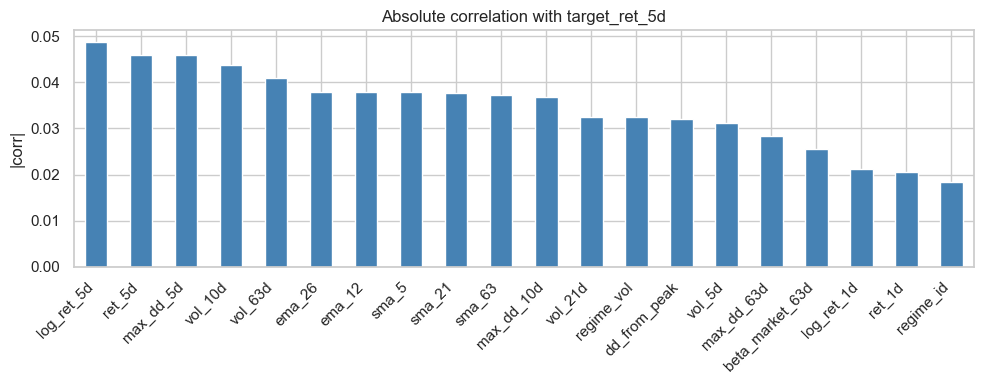

In [11]:
# Cell 9 – Feature–target correlation
# Use a numeric-only subset
num_cols = [c for c in feature_cols if panel_x[c].dtype in (np.float64, np.float32, np.int64)]
corr_with_target = (
    panel_x[num_cols + [target_ret]]
    .corr()[target_ret]
    .drop(target_ret)
    .abs()
    .sort_values(ascending=False)
)

print("Top 15 |corr| with target return:")
display(corr_with_target.head(15).to_frame("|corr|"))

# Quick visual
fig, ax = plt.subplots(figsize=(10, 4))
corr_with_target.head(20).plot.bar(ax=ax, color="steelblue")
ax.set_title(f"Absolute correlation with {target_ret}")
ax.set_ylabel("|corr|")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [12]:
## 9. Final feature matrix & train/val/test index split (chronological)

# Work on a clean matrix: features + targets + identifiers
meta_cols = ["ticker", "category"]
keep_cols = meta_cols + feature_cols + target_cols
if "regime" in panel_x.columns:
    keep_cols.append("regime")
if "regime_id" in panel_x.columns:
    keep_cols.append("regime_id")

matrix = panel_x[keep_cols].copy()
matrix = matrix.dropna(subset=[target_ret])   # final safety drop

# Global chronological split on the time index
all_dates = matrix.index.unique().sort_values()
n = len(all_dates)
train_end = all_dates[int(n * 0.70)]
val_end   = all_dates[int(n * 0.85)]

train_mask = matrix.index <= train_end
val_mask   = (matrix.index > train_end) & (matrix.index <= val_end)
test_mask  = matrix.index > val_end

print(f"Train period : {matrix.loc[train_mask].index.min().date()} → {matrix.loc[train_mask].index.max().date()}  ({train_mask.sum()} rows)")
print(f"Val   period : {matrix.loc[val_mask].index.min().date()} → {matrix.loc[val_mask].index.max().date()}  ({val_mask.sum()} rows)")
print(f"Test  period : {matrix.loc[test_mask].index.min().date()} → {matrix.loc[test_mask].index.max().date()}  ({test_mask.sum()} rows)")

matrix["split"] = "train"
matrix.loc[val_mask, "split"] = "val"
matrix.loc[test_mask, "split"] = "test"

display(matrix["split"].value_counts().to_frame("rows"))

Train period : 2022-01-10 → 2025-05-02  (31578 rows)
Val   period : 2025-05-05 → 2026-01-16  (6764 rows)
Test  period : 2026-01-20 → 2026-10-02  (6764 rows)


,rows
split,
train,31578
val,6764
test,6764


In [15]:
## 10. Persist artefacts

# --- remove duplicate columns if any ---
matrix = matrix.loc[:, ~matrix.columns.duplicated()].copy()

# 1. Full panel (parquet)
panel_path = processed_dir / "feature_panel.parquet"
matrix.to_parquet(panel_path)
print(f"Saved feature panel → {panel_path}")

# 2. Feature column list + metadata
# Rebuild clean lists from the de-duplicated matrix
feature_cols_clean = [
    c for c in matrix.columns
    if c not in ("ticker", "category", "split")
    and not c.startswith("target_")
]
target_cols_clean = [c for c in matrix.columns if c.startswith("target_")]
meta_cols_clean = [c for c in ("ticker", "category") if c in matrix.columns]

feature_meta = {
    "run_at": utc_now().isoformat(),
    "horizon": HORIZON,
    "n_tickers": int(matrix["ticker"].nunique()),
    "n_rows": int(len(matrix)),
    "feature_cols": feature_cols_clean,
    "target_cols": target_cols_clean,
    "meta_cols": meta_cols_clean,
    "train_end": str(train_end.date()),
    "val_end": str(val_end.date()),
    "failed_tickers": failed,
    "feature_groups": {
        g: [c for c in cols if c in feature_cols_clean]
        for g, cols in FEATURE_GROUPS.items()
    },
}
meta_path = processed_dir / "feature_metadata.json"
save_json(feature_meta, meta_path)
print(f"Saved feature metadata → {meta_path}")

# 3. Compact summary in MongoDB
save_analysis_result({
    "analysis_type": "feature_engineering",
    "as_of": utc_now().isoformat(),
    "payload": {
        "n_tickers": feature_meta["n_tickers"],
        "n_rows": feature_meta["n_rows"],
        "n_features": len(feature_cols_clean),
        "horizon": HORIZON,
        "train_end": feature_meta["train_end"],
        "val_end": feature_meta["val_end"],
    },
})
print("Feature-engineering summary written to MongoDB")

Saved feature panel → C:\Users\hp\Documents\GitHub\BeneathTheMarket\data\processed\feature_panel.parquet
Saved feature metadata → C:\Users\hp\Documents\GitHub\BeneathTheMarket\data\processed\feature_metadata.json
Feature-engineering summary written to MongoDB


## 11. Acceptance criteria (Notebook 03)

| Criterion | Status |
|-----------|--------|
| Causal features only (no future leakage) | Cells 4-5 |
| Targets shifted by horizon | Cell 4 |
| Regime labels built from past data | Cell 4 |
| Cross-company features attached | Cell 7 |
| Chronological train/val/test split | Cell 10 |
| Panel + metadata persisted | Cell 11 |


In [17]:
print("Notebook 03 finished successfully.")
print(f"Feature panel shape : {matrix.shape}")
print(f"Features            : {len(feature_cols)}")
print(f"Targets             : {target_cols}")

Notebook 03 finished successfully.
Feature panel shape : (45106, 44)
Features            : 39
Targets             : ['target_ret_5d', 'target_dir_5d']
